In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("../data/Job_Market_Trends.csv")

df.head(5)


,Job_ID,Posting_Date,Region,Industry_Sector,Job_Title,Experience_Level,Education_Required,Employment_Type,Work_Mode,Remote_Eligible,Minimum_Experience,Required_Skills,Monthly_Salary_PHP,Vacancies,Applicants_Count
0,JOB0001,2025-06-02,Region VII,Hospitality,Chef,Mid-level,Bachelor's,Part-time,Hybrid,No,NaN,Problem Solving; Cloud Computing,45500.0,3,60
1,JOB0002,2025-06-03,Region IV-A,Business & Finance,Marketing Associate,Mid-level,Vocational,Full-time,On-site,Yes,NaN,SQL; Project Management; Problem Solving,53500.0,7,98
2,JOB0003,2025-12-27,Region VII,Information Technology,Web Developer,Mid-level,Bachelor's,Full-time,Hybrid,Yes,3–5 years,Python; HTML/CSS; Cloud Computing,60500.0,2,73
3,JOB0004,2025-10-12,NCR,Logistics,Logistics Coordinator,Entry-level,Bachelor's,Contract,On-site,No,NaN,SQL; Data Visualization; Communication,40500.0,1,87
4,JOB0005,2025-05-10,Region I,Education,Training Specialist,Entry-level,Bachelor's,Full-time,On-site,Yes,1–2 years,HTML/CSS; Cloud Computing; Problem Solving,28000.0,2,36


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Job_ID              500 non-null    str    
 1   Posting_Date        500 non-null    str    
 2   Region              495 non-null    str    
 3   Industry_Sector     500 non-null    str    
 4   Job_Title           500 non-null    str    
 5   Experience_Level    500 non-null    str    
 6   Education_Required  495 non-null    str    
 7   Employment_Type     500 non-null    str    
 8   Work_Mode           495 non-null    str    
 9   Remote_Eligible     500 non-null    str    
 10  Minimum_Experience  325 non-null    str    
 11  Required_Skills     500 non-null    str    
 12  Monthly_Salary_PHP  495 non-null    float64
 13  Vacancies           500 non-null    int64  
 14  Applicants_Count    500 non-null    int64  
dtypes: float64(1), int64(2), str(12)
memory usage: 58.7 KB


In [3]:
print("\nMissing Values: ")
print(df.isnull().sum())


Missing Values: 
Job_ID                  0
Posting_Date            0
Region                  5
Industry_Sector         0
Job_Title               0
Experience_Level        0
Education_Required      5
Employment_Type         0
Work_Mode               5
Remote_Eligible         0
Minimum_Experience    175
Required_Skills         0
Monthly_Salary_PHP      5
Vacancies               0
Applicants_Count        0
dtype: int64


In [4]:
print("\nDuplicated Values:")
print(df.duplicated().sum())


Duplicated Values:
0


In [5]:
print("\nNumerical Summary:")
display(df.describe())


Numerical Summary:


,Monthly_Salary_PHP,Vacancies,Applicants_Count
count,495.000000,500.000000,500.000000
mean,47870.707071,4.452000,68.590000
std,14180.603824,2.825538,30.286771
min,16500.000000,1.000000,3.000000
25%,37500.000000,2.000000,48.000000
50%,47000.000000,4.000000,68.000000
75%,58000.000000,6.000000,89.000000
max,86000.000000,15.000000,151.000000


In [5]:
raw_df = df.copy()
clean_df = df.copy()

print("Original Dataset:", raw_df.shape)
print("Working Dataset:", clean_df.shape)

Original Dataset: (500, 15)
Working Dataset: (500, 15)


In [7]:
print("\nMissing Values")

missing = clean_df.isnull().sum()

print(missing[missing>0])


Missing Values
Region                  5
Education_Required      5
Work_Mode               5
Minimum_Experience    175
Monthly_Salary_PHP      5
dtype: int64


In [14]:
columns = [
    "Region",
    "Industry_Sector",
    "Job_Title",
    "Experience_Level",
    "Education_Required",
    "Employment_Type",
    "Work_Mode",
    "Remote_Eligible",
    "Required_Skills"
]

for col in columns:
    print(f"\n{col}")
    print(clean_df[col].value_counts(dropna=False))


Region
Region
NCR            130
Region IV-A     73
Region III      60
Region VI       49
Region VII      48
Region XI       46
Region I        45
Region X        44
NaN              5
Name: count, dtype: int64

Industry_Sector
Industry_Sector
Information Technology    117
Healthcare                 82
Business & Finance         74
Education                  63
Engineering                62
Hospitality                40
Logistics                  31
Manufacturing              28
IT                          3
Name: count, dtype: int64

Job_Title
Job_Title
Cybersecurity Analyst         31
Civil Engineer                28
Training Specialist           25
IT Support Specialist         25
Web Developer                 24
Radiology Technician          24
ICT Instructor                23
HR Officer                    22
Medical Technologist          22
Nurse                         21
Marketing Associate           20
Electrical Engineer           20
Financial Analyst             20
Data Anal

In [9]:
print(clean_df["Work_Mode"].value_counts(dropna=False))

for value in clean_df["Work_Mode"].dropna().unique():
    print(repr(value))

Work_Mode
On-site    281
Hybrid     122
Remote      88
NaN          5
Remote       4
Name: count, dtype: int64
'Hybrid'
'On-site'
'Remote'
'Remote '


In [11]:
clean_df["Work_Mode"] = (
    clean_df["Work_Mode"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", "", regex=True)
    .str.title()
)

print(clean_df["Work_Mode"].value_counts(dropna=False))

Work_Mode
On-Site    281
Hybrid     122
Remote      92
<NA>         5
Name: count, dtype: Int64


In [1]:
df_clean = df.copy()

df_clean["Industry_Sector"] = df_clean["Industry_Sector"].replace({
    "IT" : "Information Technology"
})

print("Information Technology:",
      (df_clean["Industry_Sector"] == "Information Technology").sum())

NameError: name 'df' is not defined

In [17]:
print("\nMissing Values")

missing = clean_df.isnull().sum()

print(missing[missing>0])


Missing Values
Region                  5
Education_Required      5
Work_Mode               5
Minimum_Experience    175
Monthly_Salary_PHP      5
dtype: int64


In [20]:
df_clean["Region"] = df_clean["Region"].fillna("Unknown")
df_clean["Education_Required"] = df_clean["Education_Required"].fillna("Not Specified")
df_clean["Work_Mode"] = df_clean["Work_Mode"].fillna("Not Specified")


In [ ]:
df_clean["Experience_Reported"] = df_clean["Minimum_Experience"].fillna("Not Specified")

group_median = df_clean.groupby(
    ["Job_Title", "Experience_Level"]
)["Monthly_Salary_PHP"].transform("median")

df_clean["Monthly_Salary_PHP"] = df_clean["Monthly_Salary_PHP"].fillna(group_median)

In [22]:
print(df.isnull().sum())

Job_ID                  0
Posting_Date            0
Region                  5
Industry_Sector         0
Job_Title               0
Experience_Level        0
Education_Required      0
Employment_Type         0
Work_Mode               0
Remote_Eligible         0
Minimum_Experience    175
Required_Skills         0
Monthly_Salary_PHP      5
Vacancies               0
Applicants_Count        0
dtype: int64


In [24]:
print("Dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Salary missing:", df_clean["Monthly_Salary_PHP"].isnull().sum())

Dataset shape: (500, 16)
Missing values: 175
Salary missing: 0


In [26]:
sector_counts = df_clean["Industry_Sector"].value_counts()

print("JOB POSTINGS BY INDUSTRY SECTOR")
print(sector_counts)

JOB POSTINGS BY INDUSTRY SECTOR
Industry_Sector
Information Technology    120
Healthcare                 82
Business & Finance         74
Education                  63
Engineering                62
Hospitality                40
Logistics                  31
Manufacturing              28
Name: count, dtype: int64


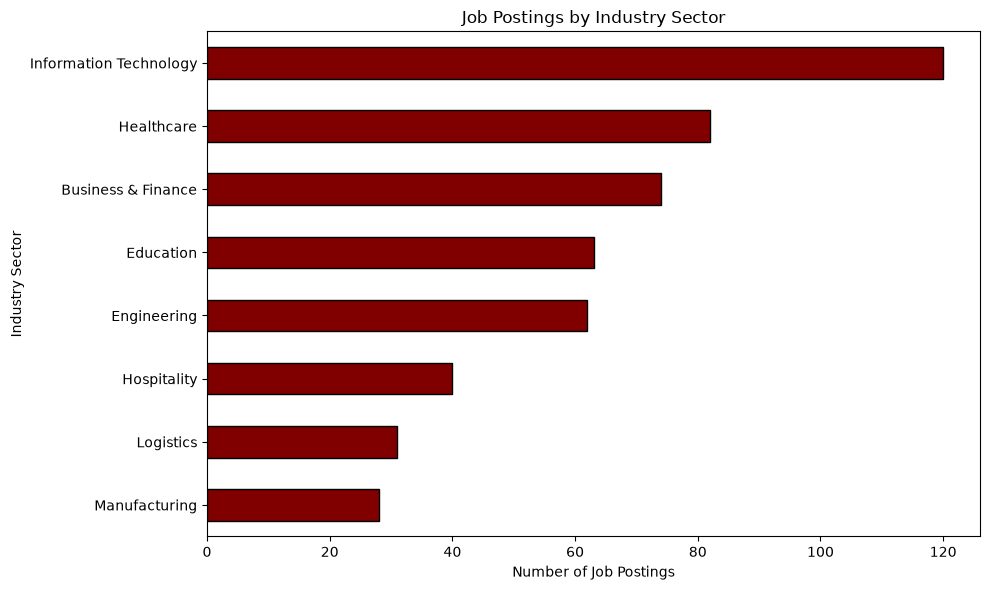

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sector_counts.sort_values().plot(
    kind="barh",
    color="800000",
    edgecolor="black"
    )


plt.title("Job Postings by Industry Sector")
plt.xlabel("Number of Job Postings")
plt.ylabel("Industry Sector")

plt.tight_layout()
plt.show()

TOP 10 MOST FREQUENT JOB TITLES
Job_Title
Cybersecurity Analyst    31
Civil Engineer           28
Training Specialist      25
IT Support Specialist    25
Web Developer            24
Radiology Technician     24
ICT Instructor           23
HR Officer               22
Medical Technologist     22
Nurse                    21
Name: count, dtype: int64


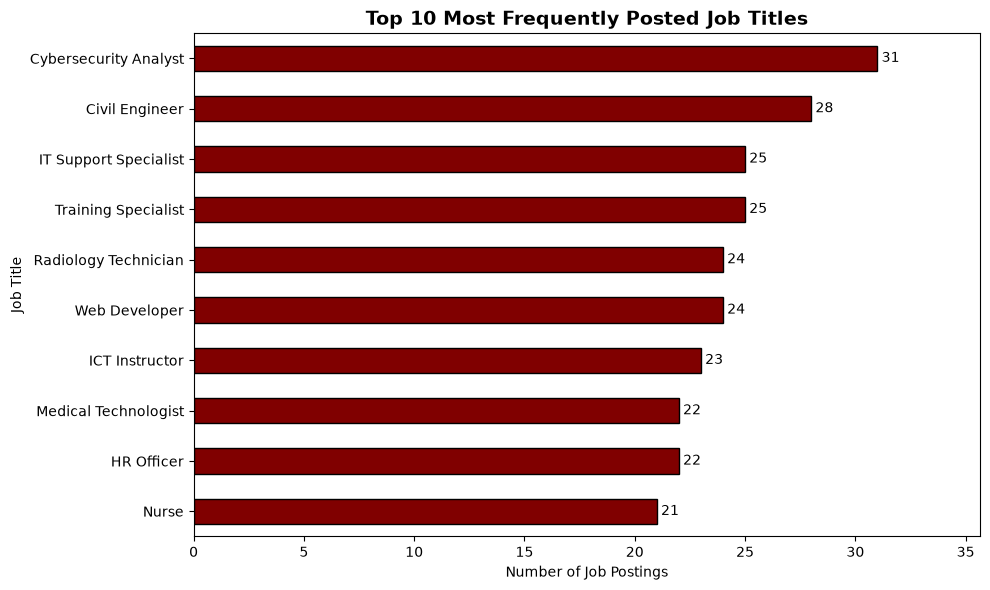

In [33]:
job_counts = df_clean["Job_Title"].value_counts()

print("TOP 10 MOST FREQUENT JOB TITLES")
print(job_counts.head(10))

plt.figure(figsize=(10, 6))

job_counts.head(10).sort_values().plot(
    kind="barh",
    color="#800000",
    edgecolor="black"
)

plt.title("Top 10 Most Frequently Posted Job Titles",
          fontsize=14, fontweight="bold")
plt.xlabel("Number of Job Postings")
plt.ylabel("Job Title")

ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.xlim(0, job_counts.head(10).max() * 1.15)
plt.tight_layout()
plt.show()

In [ ]:
region_counts = df_clean["Region"].value_counts()

print("JOB POSTINGS BY REGION")
print(region_counts)
region_counts = df_clean["Region"].value_counts()

print("JOB POSTINGS BY REGION")
print(region_counts)

plt.figure(figsize=(10, 6))

region_counts.sort_values().plot(
    kind="barh",
    color="#800000",
    edgecolor="black"
)

plt.title("Job Postings by Region",
          fontsize=14, fontweight="bold")
plt.xlabel("Number of Job Postings")
plt.ylabel("Region")

ax = plt.gca()

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.xlim(0, region_counts.max() * 1.15)
plt.tight_layout()
plt.show()

NameError: name 'df_clean' is not defined

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df_clean["Posting_Date"] = pd.to_datetime(
    df_clean["Posting_Date"],
    errors="coerce"
)

monthly_counts = (
    df_clean.groupby(
        df_clean["Posting_Date"].dt.to_period("M")
    )
    .size()
    .sort_index()
)

print("JOB POSTINGS BY MONTH")
print(monthly_counts)

NameError: name 'df_clean' is not defined

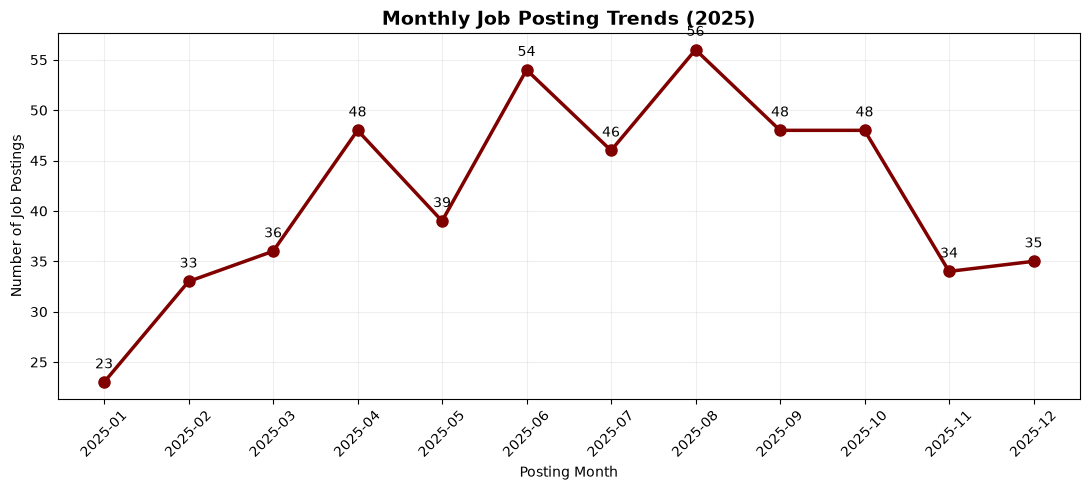

In [ ]:
plt.figure(figsize=(11, 5))

plt.plot(
    monthly_counts.index.astype(str),
    monthly_counts.values,
    color="#800000",
    marker="o",
    linewidth=2.5,
    markersize=8
)

plt.title(
    "Monthly Job Posting Trends (2025)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Posting Month")
plt.ylabel("Number of Job Postings")

# Display exact values on each point
for i, value in enumerate(monthly_counts.values):
    plt.annotate(
        str(value),
        (i, value),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

plt.xticks(rotation=45)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

MEAN AND MEDIAN SALARY BY INDUSTRY
                            mean   median
Industry_Sector                          
Manufacturing           38232.14  34750.0
Hospitality             37887.50  36500.0
Logistics               40919.35  36500.0
Education               40722.22  39000.0
Healthcare              45246.95  43750.0
Business & Finance      50672.30  48000.0
Engineering             54693.55  52250.0
Information Technology  55600.00  56000.0


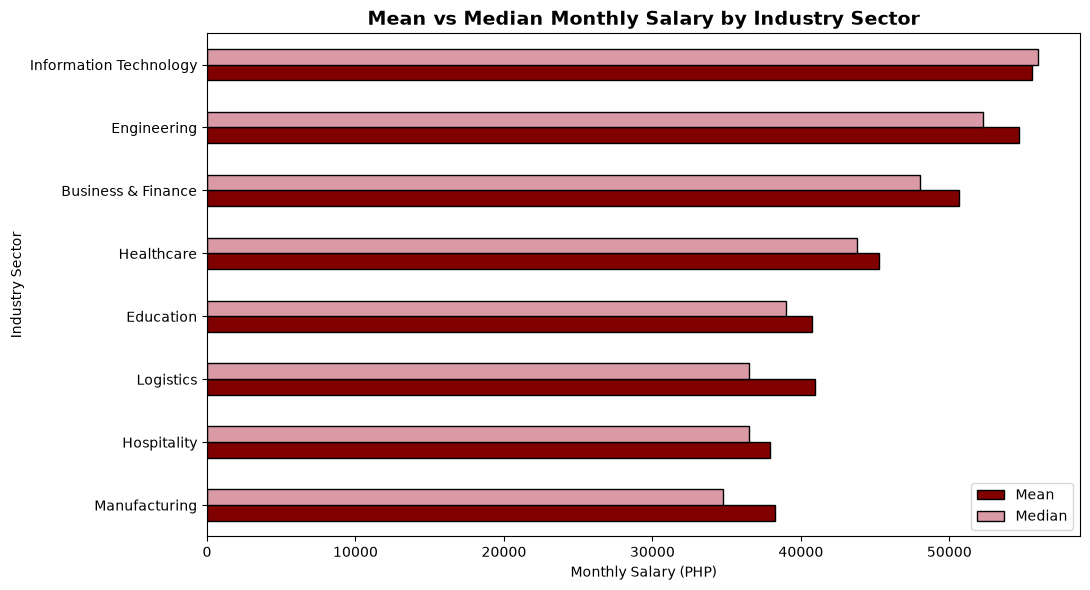

In [44]:
salary_sector = (
    df_clean.groupby("Industry_Sector")["Monthly_Salary_PHP"]
    .agg(["mean", "median"])
    .sort_values("median")
)

print("MEAN AND MEDIAN SALARY BY INDUSTRY")
print(salary_sector.round(2))

ax = salary_sector.plot(
    kind="barh",
    figsize=(11, 6),
    color=["#800000", "#D99AA5"],
    edgecolor="black"
)

plt.title("Mean vs Median Monthly Salary by Industry Sector",
          fontsize=14, fontweight="bold")
plt.xlabel("Monthly Salary (PHP)")
plt.ylabel("Industry Sector")
plt.legend(["Mean", "Median"])

plt.tight_layout()
plt.show()

MEAN AND MEDIAN SALARY BY EXPERIENCE LEVEL
                      mean   median
Experience_Level                   
Entry-level       38149.79  38000.0
Mid-level         52834.82  53125.0
Senior            64827.78  65000.0


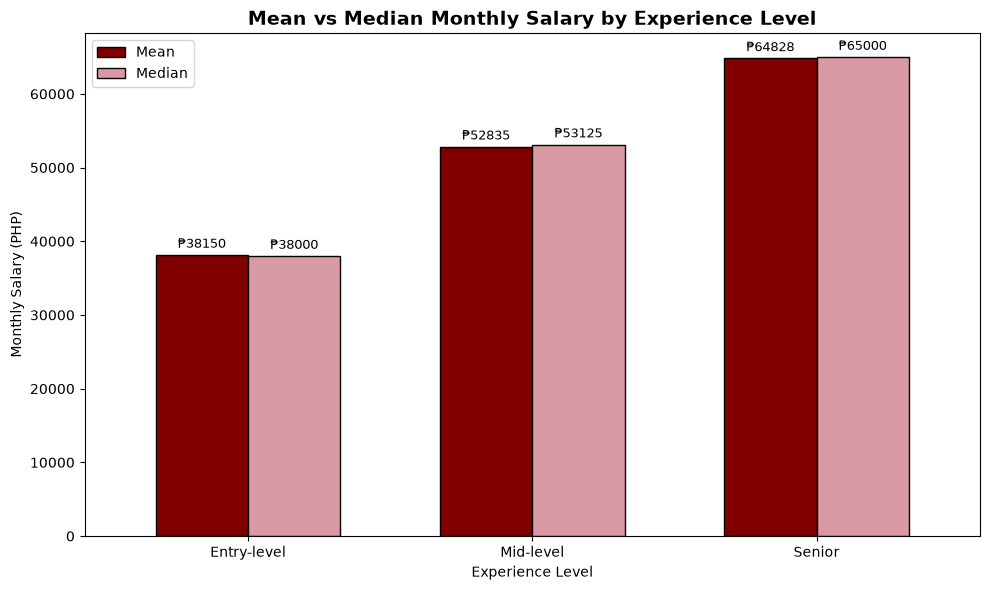

In [45]:
import matplotlib.pyplot as plt

experience_order = ["Entry-level", "Mid-level", "Senior"]

salary_experience = (
    df_clean.groupby("Experience_Level")["Monthly_Salary_PHP"]
    .agg(["mean", "median"])
    .reindex(experience_order)
)

print("MEAN AND MEDIAN SALARY BY EXPERIENCE LEVEL")
print(salary_experience.round(2))

ax = salary_experience.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#800000", "#D99AA5"],
    edgecolor="black",
    width=0.65
)

plt.title(
    "Mean vs Median Monthly Salary by Experience Level",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Experience Level")
plt.ylabel("Monthly Salary (PHP)")
plt.xticks(rotation=0)
plt.legend(["Mean", "Median"])

# Add salary labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="₱%.0f",
        padding=3,
        fontsize=9
    )

plt.tight_layout()
plt.show()

MEAN AND MEDIAN SALARY BY EDUCATION
                        mean   median
Education_Required                   
High School         38750.00  36750.0
Vocational          43482.67  42500.0
Bachelor's          47626.37  46000.0
Master's            56841.95  57500.0
Not Specified       57300.00  59500.0


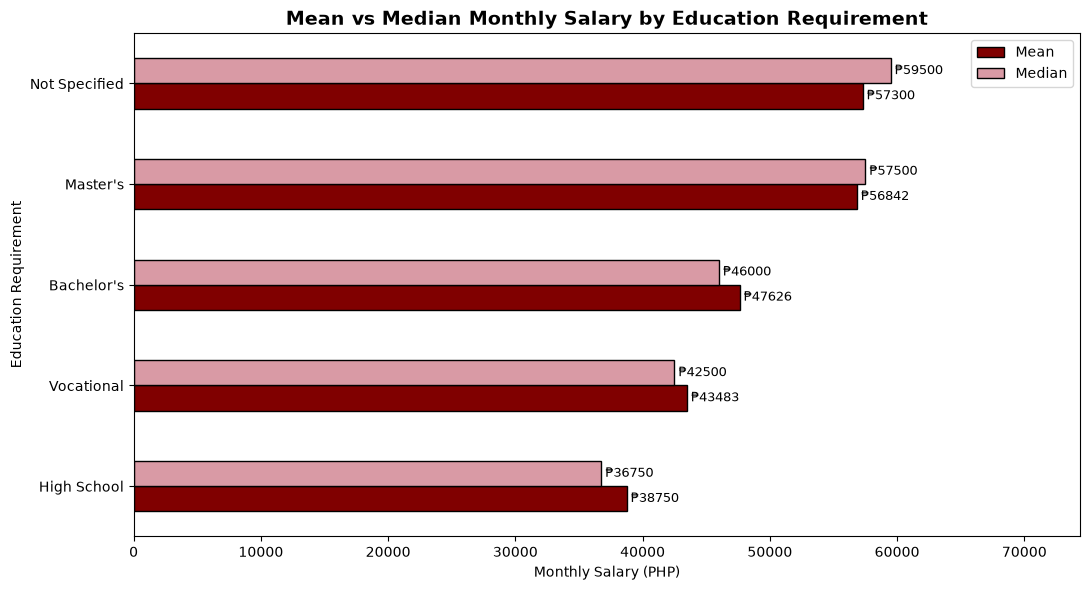

In [46]:
salary_education = (
    df_clean.groupby("Education_Required")["Monthly_Salary_PHP"]
    .agg(["mean", "median"])
    .sort_values("median")
)

print("MEAN AND MEDIAN SALARY BY EDUCATION")
print(salary_education.round(2))

ax = salary_education.plot(
    kind="barh",
    figsize=(11, 6),
    color=["#800000", "#D99AA5"],
    edgecolor="black"
)

plt.title(
    "Mean vs Median Monthly Salary by Education Requirement",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Monthly Salary (PHP)")
plt.ylabel("Education Requirement")
plt.legend(["Mean", "Median"])

# Add salary labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="₱%.0f",
        padding=3,
        fontsize=9
    )

plt.xlim(0, salary_education.max().max() * 1.25)
plt.tight_layout()
plt.show()